# Level 3, Task 2: NLP Text Classification (Sentiment Analysis)
**Codveda Technology | Data Science Internship**

**Summary of Tasks**

In this notebook I built a model that reads a short text and classifies its sentiment as Positive, Negative or Neutral. I used the sentiment dataset I was given (`Sentiment dataset.csv`). I grouped its many emotion labels into three classes, preprocessed the text (tokenisation, stopword removal and stemming), turned the text into numbers with TF-IDF, trained Naive Bayes and Logistic Regression models, and evaluated them with precision, recall and F1-score.

## 1.0 Setting Up

### 1.1 Importing the Libraries

In [6]:
import pandas as pd                                    # load and work with the data table
import numpy as np                                     # number work
import matplotlib.pyplot as plt                        # base plotting
import seaborn as sns                                  # nicer charts
from collections import Counter                        # count the most common words
from nltk.tokenize import TweetTokenizer               # split text into words (copes with hashtags and emojis)
from nltk.stem import PorterStemmer                    # reduce words to their stem
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS   # TF-IDF and a ready-made stopword list
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold   # split data and cross-validate
from sklearn.pipeline import make_pipeline             # chain TF-IDF and a model
from sklearn.naive_bayes import MultinomialNB          # model 1
from sklearn.linear_model import LogisticRegression    # model 2
from sklearn.dummy import DummyClassifier              # a "guess the most common class" baseline
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, accuracy_score,
                             precision_recall_fscore_support)   # evaluation tools

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)

**Interpretation:** The libraries loaded without errors. I used NLTK for tokenising and stemming, and scikit-learn for the stopword list, TF-IDF and the models. I used scikit-learn's built-in English stopword list instead of NLTK's, and I stemned the words instead of lemmatising them. NLTK's stopword list and its lemmatiser both need a separate download, and this way the notebook runs without any downloads.

### 1.2 Loading the Dataset

In [8]:
DATA_PATH = "sentiment_dataset.csv"    

df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
df[["Text", "Sentiment"]].head()

Rows, columns: (732, 15)


,Text,Sentiment
0,Enjoying a beautiful day at the park!,Positive
1,Traffic was terrible this morning.,Negative
2,Just finished an amazing workout! 💪,Positive
3,Excited about the upcoming weekend getaway!,Positive
4,Trying out a new recipe for dinner tonight.,Neutral


**Interpretation:** The file has 732 texts and 15 columns. I only need two of them: `Text` (the sentence) and `Sentiment` (its label). The other columns (user, platform, hashtags, likes, country and the date parts) are not used here.

## 2.0 Exploring the Data

### 2.1 Data Quality Checks

In [9]:
df = df[["Text", "Sentiment"]].copy()          # these are the only two columns I need
df["Text"] = df["Text"].str.strip()            # remove stray spaces around the text and the labels
df["Sentiment"] = df["Sentiment"].str.strip()

print("Missing values:")
print(df.isnull().sum())
print("\nRepeated texts:", df.duplicated("Text").sum())
conflict = df[df.duplicated("Text", keep=False)].groupby("Text")["Sentiment"].nunique()
print("Repeated texts that have different labels:", (conflict > 1).sum())
print("\nText length in characters:")
print(df["Text"].str.len().describe().round(0))

Missing values:
Text         0
Sentiment    0
dtype: int64

Repeated texts: 26
Repeated texts that have different labels: 0

Text length in characters:
count    732.0
mean      84.0
std       31.0
min       27.0
25%       56.0
50%       82.0
75%      108.0
max      156.0
Name: Text, dtype: float64


**Interpretation:** There are no missing values. There are 26 repeated texts, and none of them has two different labels. The texts are short: about 84 characters on average (around 13 words), from 27 to 156 characters. I remove the repeated texts in step 3.3. A repeated sentence in both the training and test sets would let the model recognise something it has already seen.

### 2.2 A Look at Some Texts

In [12]:
df.sample(10, random_state=1)

,Text,Sentiment
404,Whispers of inspiration from the rustling leaves in a serene forest.,Inspiration
646,"Daydreaming about the upcoming prom. The dress, the dance – it's a fairytale in the making!",Excitement
159,Enthusiasm for a DIY home improvement project.,Enthusiasm
449,"Avoiding the shards of shattered dreams, walking the tightrope of resilience.",Resilience
699,Having a bad hair day and feeling self-conscious. Bad hair days can affect confidence.,Bad
241,"Ambivalence in the air, caught between the crossroads of conflicting emotions and decisions.",Ambivalence
639,"Attended a local jazz festival, tapping toes to the tunes that have stood the test of time. Music, a lifel...",Joy
247,"Dancing through life with the exuberance of a carefree spirit, embracing joy and zest at every turn.",Zest
355,Anticipation for an upcoming adventure in an exotic destination.,Anticipation
445,"In the ruins of hope, echoes of shattered dreams whisper tales of loss.",Desolation


**Interpretation:** The texts are short sentences about feelings and situations, and each one has a specific emotion as its label (for example Inspiration, Excitement, Bad, Ambivalence). Many texts contain the emotion word itself, such as "Ambivalence in the air..." and "Enthusiasm for a DIY home improvement project". A model can therefore do well partly by spotting those words, and I kept this in mind when I read the results.

### 2.3 The Label Problem

In [15]:
counts = df["Sentiment"].value_counts()
print("Different labels:", counts.size)
print("Labels that appear only once:", (counts == 1).sum())
print("Labels that appear fewer than 5 times:", (counts < 5).sum())
counts.head(10)

Different labels: 191
Labels that appear only once: 79
Labels that appear fewer than 5 times: 148


Sentiment
Positive       45
Joy            44
Excitement     37
Contentment    19
Neutral        18
Gratitude      18
Curiosity      16
Serenity       15
Happy          14
Despair        11
Name: count, dtype: int64

**Interpretation:** There are 191 different labels, 79 of them appear only once, and 148 appear fewer than 5 times. The most common are Positive (45), Joy (44) and Excitement (37). With 732 texts spread over 191 labels, a model cannot learn each label separately, so I have to group them first.

## 3.0 Preparing the Labels

### 3.1 Grouping the Labels into Three Classes
With 191 different labels, most of them with only one to three examples, a model cannot learn each one separately. I grouped them by whether the emotion is pleasant, unpleasant, or neutral/mixed. This grouping is my own judgement (the dataset does not come with one), so I showed the full lists in the code below, so that anyone can check or change them.

In [17]:
# Positive: pleasant emotions. Negative: unpleasant emotions.
# Neutral: no clear feeling, or mixed feelings (for example nostalgia, acceptance, surprise).
positive = [
    "Positive", "Joy", "Excitement", "Contentment", "Gratitude", "Curiosity", "Serenity", "Happy",
    "Hopeful", "Awe", "Pride", "Elation", "Euphoria", "Enthusiasm", "Determination", "Playful",
    "Inspiration", "Happiness", "Hope", "Empowerment", "Inspired", "Admiration", "Calmness",
    "Compassion", "Tenderness", "Arousal", "Fulfillment", "Reverence", "Proud", "Grateful",
    "Compassionate", "Thrill", "Enchantment", "Love", "Amusement", "Anticipation", "Kind",
    "Empathetic", "Free-spirited", "Confident", "Satisfaction", "Accomplishment", "Harmony",
    "Creativity", "Wonder", "Adventure", "Enjoyment", "Affection", "Adoration", "Zest", "Whimsy",
    "Radiance", "Rejuvenation", "Coziness", "Resilience", "Exploration", "Captivation",
    "Tranquility", "Mischievous", "Overjoyed", "Motivation", "JoyfulReunion", "Blessed",
    "Appreciation", "Confidence", "Wonderment", "Optimism", "Intrigue", "PlayfulJoy",
    "Mindfulness", "DreamChaser", "Elegance", "Melodic", "FestiveJoy", "InnerJourney", "Freedom",
    "Dazzle", "Adrenaline", "ArtisticBurst", "CulinaryOdyssey", "Immersion", "Spark", "Marvel",
    "Positivity", "Kindness", "Friendship", "Success", "Amazement", "Romance", "Grandeur",
    "Energy", "Celebration", "Charm", "Ecstasy", "Colorful", "Hypnotic", "Connection", "Iconic",
    "Journey", "Engagement", "Touched", "Suspense", "Triumph", "Heartwarming", "Renewed Effort",
    "Solace", "Breakthrough", "Joy in Baking", "Imagination", "Vibrancy", "Mesmerizing",
    "Culinary Adventure", "Winter Magic", "Thrilling Journey", "Nature's Beauty",
    "Celestial Wonder", "Creative Inspiration", "Runway Creativity", "Ocean's Freedom", "Relief"
]

negative = [
    "Despair", "Grief", "Loneliness", "Sad", "Embarrassed", "Frustration", "Regret", "Numbness",
    "Melancholy", "Hate", "Bad", "Disgust", "Bitterness", "Frustrated", "Betrayal", "Negative",
    "Boredom", "Overwhelmed", "Desolation", "Bitter", "Shame", "Jealousy", "Resentment",
    "Fearful", "Jealous", "Devastated", "Envious", "Dismissive", "Heartbreak", "Anger", "Fear",
    "Sadness", "Disappointed", "Anxiety", "Intimidation", "Helplessness", "Envy", "Yearning",
    "Apprehensive", "Isolation", "Disappointment", "Sorrow", "Loss", "Suffering",
    "EmotionalStorm", "LostLove", "Exhaustion", "Darkness", "Desperation", "Ruins", "Heartache",
    "Obstacle", "Pressure", "Miscalculation", "Challenge", "Confusion"
]

neutral = [
    "Neutral", "Nostalgia", "Acceptance", "Surprise", "Indifference", "Ambivalence", "Reflection",
    "Contemplation", "Pensive", "Bittersweet", "Emotion", "Solitude", "Sympathy",
    "Whispers of the Past", "Envisioning History"
]

group = {}
for names, class_name in [(positive, "Positive"), (negative, "Negative"), (neutral, "Neutral")]:
    for label in names:
        group[label] = class_name

print("Labels not placed in any group:", set(df["Sentiment"]) - set(group))
df["label"] = df["Sentiment"].map(group)
df[["Sentiment", "label"]].sample(8, random_state=3)

Labels not placed in any group: set()


,Sentiment,label
80,Happiness,Positive
97,Kind,Positive
559,Despair,Negative
406,Gratitude,Positive
124,Contentment,Positive
546,Awe,Positive
126,Gratitude,Positive
216,Curiosity,Positive


**Interpretation:** All 191 labels were placed in a group, and the empty set in the output confirms that none was missed. The sample shows the idea: Happiness, Kind, Gratitude, Contentment, Awe and Curiosity go to Positive, and Despair goes to Negative. Some choices are judgement calls. I put Curiosity, Awe and Anticipation in Positive, Confusion, Numbness and Boredom in Negative, and Nostalgia, Acceptance, Surprise, Indifference and Ambivalence in Neutral. Someone else might group a few differently, and the grouping affects the results.

### 3.2 Class Balance

          texts  share (%)
label                     
Positive    467       63.8
Negative    196       26.8
Neutral      69        9.4


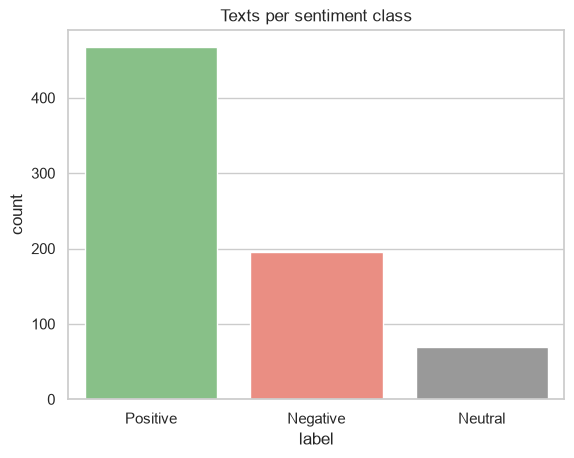

In [19]:
class_counts = df["label"].value_counts()
print(pd.DataFrame({"texts": class_counts, "share (%)": (class_counts / len(df) * 100).round(1)}))

sns.countplot(x="label", data=df, order=["Positive", "Negative", "Neutral"],
              hue="label", palette=["#7fc97f", "#fb8072", "#999999"], legend=False)
plt.title("Texts per sentiment class")
plt.show()

**Interpretation:** The classes are imbalanced: Positive has 467 texts (63.8%), Negative 196 (26.8%) and Neutral only 69 (9.4%). A model that always answered Positive would already be right about 64% of the time, so accuracy alone will be misleading. I will pay attention to precision, recall and the macro F1 score, which gives each class the same weight, and in particular to how well the small Neutral class is handled.

### 3.3 Removing the Repeated Texts

In [21]:
rows_before = len(df)
df = df.drop_duplicates("Text").reset_index(drop=True)

print("Rows before:", rows_before, "| after:", len(df))
df["label"].value_counts()

Rows before: 706 | after: 706


label
Positive    445
Negative    192
Neutral      69
Name: count, dtype: int64

**Interpretation:** I removed the 26 repeated texts, leaving 706 (445 Positive, 192 Negative and 69 Neutral). I did this so that the same sentence cannot end up in both the training and test sets, which would make the test score look better than it is. Since none of the repeated texts had conflicting labels, no information was lost.

## 4.0 Text Preprocessing

### 4.1 The Steps on One Example

In [24]:
tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
stemmer = PorterStemmer()

# I kept negations like "not" and "never", because they can flip the meaning of a sentence
negations = {"not", "no", "nor", "never", "cannot", "nothing", "nobody", "none", "neither", "without"}
stop_words = ENGLISH_STOP_WORDS - negations

example = df["Text"][2]
tokens = tokenizer.tokenize(example)                                    # 1. lower case and split into tokens
words = [t.lstrip("#") for t in tokens]
words = [w for w in words if w.isalpha()]                               # 2. keep words only
no_stop = [w for w in words if w not in stop_words]                     # 3. remove stopwords
stems = [stemmer.stem(w) for w in no_stop]                              # 4. reduce each word to its stem

print("Original  :", example)
print("Tokens    :", tokens)
print("Words     :", words)
print("No stops  :", no_stop)
print("Stems     :", stems)

Original  : Just finished an amazing workout! 💪
Tokens    : ['just', 'finished', 'an', 'amazing', 'workout', '!', '💪']
Words     : ['just', 'finished', 'an', 'amazing', 'workout']
No stops  : ['just', 'finished', 'amazing', 'workout']
Stems     : ['just', 'finish', 'amaz', 'workout']


**Interpretation:** This shows each step on one text. The tokeniser splits the sentence into pieces and makes them lower case. I keep only real words, so the punctuation and the emoji are dropped (emoji are rare in this data, so little is lost). Then the stopwords such as "an" are removed, and each word is reduced to its stem, for example "finished" becomes "finish" and "amazing" becomes "amaz". The stems can look odd, but they let related words match each other ("amazing" and "amazed" give the same stem). I kept negations like "not" and "never" out of the stopword list, because they can reverse the meaning of a sentence.

### 4.2 Applying the Preprocessing to Every Text

In [25]:
def preprocess(text):
    tokens = tokenizer.tokenize(text)
    words = [t.lstrip("#") for t in tokens]
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return " ".join(stemmer.stem(w) for w in words)

df["clean"] = df["Text"].apply(preprocess)

print("Texts that became empty after cleaning:", (df["clean"] == "").sum())
print("Average words per text before:", round(df["Text"].str.split().str.len().mean(), 1),
      "| after:", round(df["clean"].str.split().str.len().mean(), 1))
df[["Text", "clean"]].sample(5, random_state=2)

Texts that became empty after cleaning: 0
Average words per text before: 13.0 | after: 7.7


,Text,clean
107,Pride in accomplishing personal and professional goals.,pride accomplish person profession goal
399,"Aching heart, the symphony of pain plays in the silence of solitude.",ach heart symphoni pain play silenc solitud
221,"Flipping through the pages of an old yearbook, nostalgia painting smiles and tears on my face.",flip page old yearbook nostalgia paint smile tear face
37,Practicing mindfulness with meditation.,practic mind medit
524,"After a series of defeats, the soccer team faces disappointment, struggling to find the silver lining in a...",seri defeat soccer team face disappoint struggl silver line challeng season


**Interpretation:** No text became empty after cleaning, and the average text went from 13.0 words to 7.7. The examples show the result: "Pride in accomplishing personal and professional goals." became "pride accomplish person profession goal". Some stems look strange ("symphoni", "silenc"), but they are consistent across texts, which is what the model needs.

### 4.3 The Most Common Words in Each Class

In [26]:
top_words = {}
for class_name in ["Positive", "Negative", "Neutral"]:
    words_in_class = " ".join(df.loc[df["label"] == class_name, "clean"]).split()
    top_words[class_name] = [f"{w} ({c})" for w, c in Counter(words_in_class).most_common(8)]
pd.DataFrame(top_words)

,Positive,Negative,Neutral
0,new (36),echo (17),embrac (9)
1,joy (29),like (15),old (8)
2,challeng (22),despair (14),nostalgia (8)
3,danc (22),feel (13),day (7)
4,beauti (20),emot (13),accept (7)
5,explor (19),heart (12),emot (7)
6,seren (19),lost (12),new (6)
7,friend (18),shatter (12),find (6)


**Interpretation:** The most common words give a first feel for each class. Negative texts often contain echo, despair, heart, lost and shatter. Positive texts contain joy, danc, beauti, seren and friend. The Neutral list is a mix (embrac, old, nostalgia, accept), which fits that class being a collection of mixed feelings. Some words, like "new" and "emot", appear in more than one class, so common does not always mean useful. TF-IDF will reduce the weight of words that appear everywhere.

## 5.0 Splitting the Data

### 5.1 Train/Test Split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])

print("Training texts:", len(X_train), "| Testing texts:", len(X_test))
print(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

Training texts: 564 | Testing texts: 142
          train  test
label                
Positive    356    89
Negative    153    39
Neutral      55    14


**Interpretation:** I used 564 texts for training and 142 for testing. The stratified split keeps the class proportions the same in both sets (Positive 356/89, Negative 153/39, Neutral 55/14). The Neutral class has only 14 test texts, so its scores can change a lot with a single text. I split the data before building the TF-IDF vocabulary, so the vocabulary comes from the training texts only.

## 6.0 Turning Text into Numbers with TF-IDF

### 6.1 Fitting TF-IDF on the Training Texts

In [28]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)    # single words and pairs of words, seen in at least 2 texts
Xtr = tfidf.fit_transform(X_train)                       # learn the vocabulary from the training texts only
Xte = tfidf.transform(X_test)

print("Training matrix:", Xtr.shape, "| Testing matrix:", Xte.shape)
print("Share of non-zero cells: %.2f%%" % (Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]) * 100))

Training matrix: (564, 972) | Testing matrix: (142, 972)
Share of non-zero cells: 0.71%


**Interpretation:** TF-IDF turns each text into a row of numbers, with one column per word or pair of words. A word gets a high weight when it appears often in a text but is rare across all the texts. I used single words and pairs of words (so "not happy" is kept together), and only the terms that appear in at least 2 training texts, since a term seen once cannot help with new texts. The training matrix has 564 rows and 972 columns. Only 0.71% of the cells are non-zero, because each short text uses just a few of the 972 terms.

### 6.2 The Highest-Weighted Terms

In [29]:
average_weight = pd.Series(Xtr.mean(axis=0).A1, index=tfidf.get_feature_names_out())
average_weight.sort_values(ascending=False).head(10).round(3)

new         0.015
day         0.014
challeng    0.014
danc        0.013
joy         0.013
like        0.012
feel        0.012
beauti      0.012
moment      0.011
night       0.011
dtype: float64

**Interpretation:** These are the terms with the highest average TF-IDF weight, such as "new", "day", "challeng", "danc" and "joy". The weights are small (around 0.015), and the list is just the most frequent terms, not necessarily the most useful ones for telling the classes apart. I look at the terms that actually drive the predictions in section 9.

## 7.0 Training and Evaluating the Models

### 7.1 A Baseline to Beat

In [30]:
def summary(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f}

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
rows = [summary("Baseline (always the most common class)", y_test, dummy.predict(Xte))]
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Baseline (always the most common class),0.627,0.209,0.333,0.257


**Interpretation:** A model that always predicts the most common class (Positive) gets an accuracy of 0.627 and a macro F1 of only 0.257. Macro scores average the three classes with equal weight, so the small Neutral class counts as much as Positive. These are the numbers my models have to beat.

### 7.2 Naive Bayes

In [31]:
nb = MultinomialNB()
nb.fit(Xtr, y_train)
pred_nb = nb.predict(Xte)

print(classification_report(y_test, pred_nb, digits=3, zero_division=0))

              precision    recall  f1-score   support

    Negative      0.963     0.667     0.788        39
     Neutral      1.000     0.214     0.353        14
    Positive      0.786     0.989     0.876        89

    accuracy                          0.824       142
   macro avg      0.916     0.623     0.672       142
weighted avg      0.856     0.824     0.800       142



**Interpretation:** Naive Bayes has an accuracy of 0.824 and a macro F1 of 0.672. Precision is how often a prediction is right, and recall is how many of the real cases were found. For Positive, recall is 0.989 (it found 88 of 89), but precision is lower (0.786) because other classes get mixed in. For Neutral, precision is 1.000 but recall is only 0.214: when the model says Neutral it is always right, but it found just 3 of the 14 Neutral texts because it almost never says Neutral.

### 7.3 Logistic Regression

In [32]:
lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr, y_train)
pred_lr = lr.predict(Xte)

print(classification_report(y_test, pred_lr, digits=3, zero_division=0))

              precision    recall  f1-score   support

    Negative      0.926     0.641     0.758        39
     Neutral      1.000     0.143     0.250        14
    Positive      0.770     0.978     0.861        89

    accuracy                          0.803       142
   macro avg      0.899     0.587     0.623       142
weighted avg      0.835     0.803     0.773       142



**Interpretation:** Logistic regression follows the same pattern, slightly worse: accuracy 0.803 and macro F1 0.623. It finds only 2 of the 14 Neutral texts (recall 0.143) and 25 of the 39 Negative ones (0.641). With so few Neutral and Negative examples, the model leans towards the biggest class, Positive.

### 7.4 Handling the Imbalance with Class Weights

In [33]:
# class_weight="balanced" makes mistakes on the small classes count more during training
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_bal.fit(Xtr, y_train)
pred_lr_bal = lr_bal.predict(Xte)

print(classification_report(y_test, pred_lr_bal, digits=3, zero_division=0))

              precision    recall  f1-score   support

    Negative      0.846     0.846     0.846        39
     Neutral      0.400     0.429     0.414        14
    Positive      0.886     0.876     0.881        89

    accuracy                          0.824       142
   macro avg      0.711     0.717     0.714       142
weighted avg      0.827     0.824     0.826       142



**Interpretation:** With class weights, mistakes on the small classes count more during training. Accuracy stays at 0.824, and the macro F1 improves to 0.714. The model now finds 6 of the 14 Neutral texts (recall 0.429, precision 0.400) and 33 of the 39 Negative texts (recall 0.846). The price is that Positive recall drops from about 0.98 to 0.876, because some Positive texts are now labelled Negative or Neutral. The results are more evenly spread across the three classes.

### 7.5 Comparing the Models

In [34]:
rows += [summary("Naive Bayes", y_test, pred_nb),
         summary("Logistic Regression", y_test, pred_lr),
         summary("Logistic Regression (balanced)", y_test, pred_lr_bal)]
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Baseline (always the most common class),0.627,0.209,0.333,0.257
Naive Bayes,0.824,0.916,0.623,0.672
Logistic Regression,0.803,0.899,0.587,0.623
Logistic Regression (balanced),0.824,0.711,0.717,0.714


**Interpretation:** All the models beat the baseline easily (accuracy 0.627 and macro F1 0.257). Naive Bayes and the balanced logistic regression tie on accuracy (0.824), but the balanced logistic regression has the best macro F1 (0.714) and the best macro recall (0.717), while Naive Bayes has the highest macro precision (0.916) because it hardly ever predicts the small classes. Since I want the model to handle all three classes, I prefer the balanced logistic regression.

### 7.6 Confusion Matrices

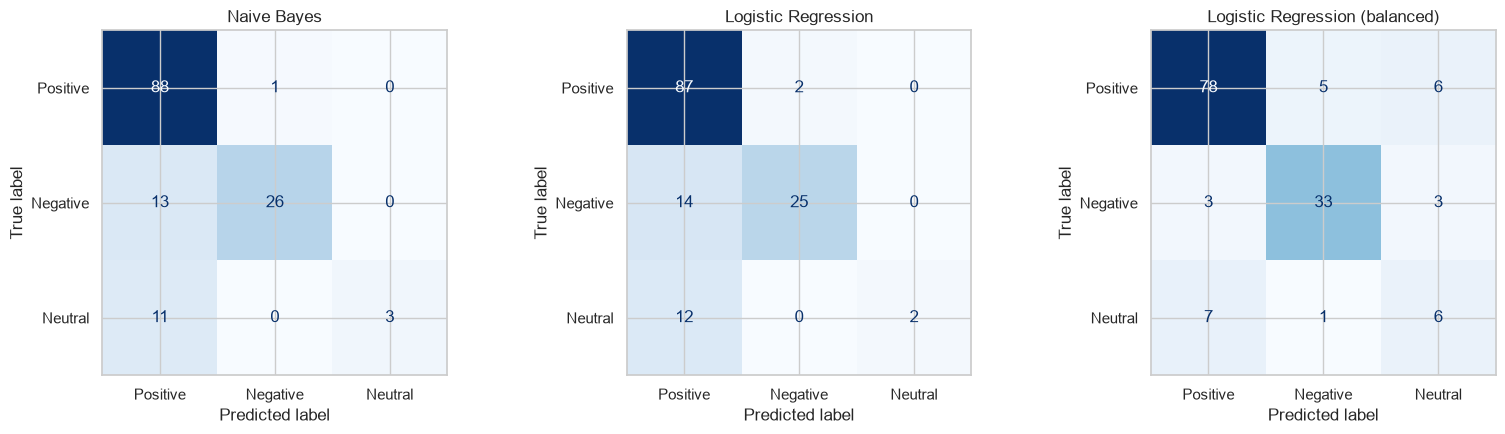

In [35]:
labels_order = ["Positive", "Negative", "Neutral"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, [("Naive Bayes", pred_nb), ("Logistic Regression", pred_lr),
                                   ("Logistic Regression (balanced)", pred_lr_bal)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels_order, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretation:** Naive Bayes and plain logistic regression send most of the Neutral texts to Positive (11 and 12 of the 14), and about a third of the Negative texts (13 and 14 of 39) as well. The balanced model gets 78 of 89 Positive, 33 of 39 Negative and 6 of 14 Neutral right, and its mistakes are spread between the classes instead of all falling into Positive.

## 8.0 Cross-Validation

### 8.1 Five-Fold Cross-Validation

In [36]:
# the test set is small, so I repeat the evaluation on 5 different splits of all the texts
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

cv_rows = {}
for name, model in cv_models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), model)
    f1 = cross_val_score(pipe, df["clean"], df["label"], cv=skf, scoring="f1_macro")
    acc = cross_val_score(pipe, df["clean"], df["label"], cv=skf, scoring="accuracy")
    cv_rows[name] = {"Mean accuracy": acc.mean(), "Mean macro F1": f1.mean(), "F1 std": f1.std(), "Lowest fold F1": f1.min()}
pd.DataFrame(cv_rows).T.round(3)

,Mean accuracy,Mean macro F1,F1 std,Lowest fold F1
Naive Bayes,0.820,0.592,0.039,0.535
Logistic Regression,0.799,0.592,0.049,0.530
Logistic Regression (balanced),0.846,0.732,0.037,0.692


**Interpretation:** The test set is small, so I repeated the evaluation on 5 different splits of all the texts. The balanced logistic regression is best again: accuracy 0.846 and macro F1 0.732, against macro F1 of 0.592 for both Naive Bayes and plain logistic regression. Even its worst fold (0.692) is better than the worst fold of the others (0.535 and 0.530). So the benefit of class weights holds up across splits, and it is not luck.

## 9.0 Understanding the Model

### 9.1 Which Words Push the Prediction Towards Each Class?

In [37]:
feature_names = tfidf.get_feature_names_out()
top_features = {}
for i, class_name in enumerate(lr_bal.classes_):
    best = np.argsort(lr_bal.coef_[i])[::-1][:10]
    top_features[class_name] = [feature_names[j] for j in best]
pd.DataFrame(top_features)

,Negative,Neutral,Positive
0,despair,accept,seren
1,loneli,nostalgia,joy
2,disappoint,contempl,inspir
3,bitter,indiffer,laughter
4,grief,ambival,celebr
5,bad,embrac,creativ
6,linger,old,gratitud
7,thought,emot,creat
8,fear,find accept,embark
9,frustrat,surpris,music


**Interpretation:** These are the terms with the strongest push towards each class in the balanced model. For Negative: despair, loneliness, disappointment, bitter, grief, fear and frustration. For Positive: serenity, joy, inspiration, laughter, celebration and gratitude. For Neutral: accept, nostalgia, contemplation, indifference, ambivalence and surprise. The model has mostly learned emotion words, which makes sense because many texts contain the very emotion word that defines their label. The Neutral words are the ones I put into the Neutral group, so that class depends on my grouping.

### 9.2 Looking at the Mistakes

In [38]:
errors = pd.DataFrame({"text": df.loc[X_test.index, "Text"], "true": y_test, "predicted": pred_lr_bal})
errors = errors[errors["true"] != errors["predicted"]]

print("Mistakes:", len(errors), "out of", len(y_test))
errors.head(8)

Mistakes: 25 out of 142


,text,true,predicted
671,Facing rejection from a dream college. Disheartened but determined to explore other paths.,Negative,Positive
549,"At the astronomy observatory, the stargazer marvels at the vastness of the cosmos, contemplating the myste...",Positive,Neutral
641,Accidentally sent a text meant for a friend to the class group chat. Texting fail: Oops moment!,Negative,Neutral
9,Missing summer vibes and beach days.,Neutral,Negative
553,"Exploring the historical architecture of an ancient city, the traveler is transported to a bygone era, whe...",Neutral,Positive
14,Technology is changing the way we live.,Neutral,Positive
5,Feeling grateful for the little things in life.,Positive,Negative
654,Building a time capsule to capture memories for the future. Time-traveling emotions!,Positive,Neutral


**Interpretation:** The balanced model made 25 mistakes out of 142 texts. Many of them involve mixed feelings or neutral statements. "Facing rejection from a dream college. Disheartened but determined to explore other paths" is labelled Negative but also contains a hopeful part, and the model said Positive. "Technology is changing the way we live" is Neutral but was predicted Positive. "Feeling grateful for the little things in life" is Positive but was predicted Negative, possibly because the word "feel" appears often in the Negative texts. These errors show that, with so little data, the model relies on single words and cannot read the whole meaning of a sentence.

## 10.0 Conclusion

### 10.1 Results (Test Set of 142 Texts)
| Model | Accuracy | Macro precision | Macro recall | Macro F1 | Cross-validated macro F1 |
|---|---|---|---|---|---|
| Baseline (always Positive) | 0.627 | 0.209 | 0.333 | 0.257 | - |
| Naive Bayes | 0.824 | 0.916 | 0.623 | 0.672 | 0.592 |
| Logistic Regression | 0.803 | 0.899 | 0.587 | 0.623 | 0.592 |
| **Logistic Regression (balanced)** | **0.824** | 0.711 | **0.717** | **0.714** | **0.732** |

### 10.2 What I Found
1. **The 191 labels had to be grouped.** I grouped them into Positive, Negative and Neutral, which gave an imbalanced dataset (64%, 27% and 9%).
2. **All the models beat the baseline,** but Naive Bayes and plain logistic regression mostly ignored the small Neutral class (they found 3 and 2 of the 14 Neutral test texts).
3. **Class weights helped.** The balanced logistic regression is the best overall, with a cross-validated macro F1 of 0.732 against 0.592 for the others, and it found 6 of the 14 Neutral texts.
4. **The model learned emotion keywords** such as despair, joy and nostalgia, rather than understanding whole sentences.
5. **The remaining mistakes** are mostly texts with mixed feelings or a neutral tone.

### 10.3 Limitations
- The grouping of labels is my own judgement, and a different grouping would change the results.
- The Neutral class has only 69 texts (14 in the test set), so its scores are not very stable.
- Many texts contain the emotion word that defines their label, so these results probably overstate how well the model would do on everyday text.
- I used stemming instead of lemmatisation, and I did not tune the TF-IDF settings or the models.

### 10.4 Possible Next Steps
Review the label grouping with someone else, collect more Neutral examples, try lemmatisation or word embeddings such as Word2Vec, and test other models such as a linear SVM.